In [1]:
# ==========================================
# CELL 1: INSTALLATION & SETUP
# ==========================================
# Make sure you have installed: pip install torch torchvision torchaudio torch-geometric timm albumentations opencv-python pandas matplotlib seaborn scikit-learn

import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torch_geometric.nn import GATv2Conv
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

# Set Device to your local 4060 Ti
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Setup Complete. Using {device}: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

✅ Setup Complete. Using cuda: NVIDIA GeForce RTX 4060 Ti


In [2]:
# ==========================================
# CELL 2: FINAL DATASET LOADER
# ==========================================

# DEFINE LOCAL PATH based on your VS Code screenshot
dataset_root = "dataset/FracAtlas-20260307T050746Z-1-001/FracAtlas"
csv_path = os.path.join(dataset_root, "dataset.csv")

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"❌ CRITICAL: Could not find dataset.csv at {csv_path}. Please verify the folder name.")

print(f"✅ Found Annotation File: {csv_path}")

# DATASET CLASS
class FracAtlasDataset(Dataset):
    def __init__(self, root_dir, annotation_file, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.data = pd.read_csv(annotation_file)
        self.valid_data = []
        
        print(f"🔍 Scanning images... (This may take a moment)")

        id_col = 'image_id'      
        target_col = 'fractured' 
        missing_count = 0

        for idx, row in self.data.iterrows():
            img_name = row.get(id_col)
            try:
                raw_val = row.get(target_col, 0)
                label = int(raw_val)
            except:
                label = 0

            subfolder = "Fractured" if label == 1 else "Non_fractured"
            img_path = os.path.join(self.root_dir, "images", subfolder, str(img_name))

            if os.path.exists(img_path):
                self.valid_data.append({'path': img_path, 'label': float(label)})
            else:
                missing_count += 1

        fracture_count = sum(1 for x in self.valid_data if x['label'] == 1.0)
        healthy_count = sum(1 for x in self.valid_data if x['label'] == 0.0)
        print(f"✅ LOADED: {len(self.valid_data)} total images. (Missing: {missing_count})")
        print(f"📊 BREAKDOWN: {fracture_count} Fractures | {healthy_count} Healthy")

    def __getitem__(self, idx):
        row = self.valid_data[idx]
        image = cv2.imread(row['path'])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # CLAHE
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
        cl = clahe.apply(l)
        limg = cv2.merge((cl,a,b))
        image = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

        if self.transform:
            augmented = self.transform(image=image)
            image = augmented['image']

        return image, torch.tensor(row['label'], dtype=torch.float32)

    def __len__(self):
        return len(self.valid_data)

# TRANSFORMS
train_transforms = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=20, p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# INITIALIZE
try:
    full_dataset = FracAtlasDataset(dataset_root, csv_path, train_transforms)

    train_size = int(0.8 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])
    val_dataset.dataset.transform = val_transforms

    # Increased num_workers for local GPU efficiency (adjust based on your CPU cores)
    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=4, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)

    print(f"\n🚀 SUCCESS: DataLoaders Ready!")
except Exception as e:
    print(f"\n❌ ERROR: {e}")

✅ Found Annotation File: dataset/FracAtlas-20260307T050746Z-1-001/FracAtlas/dataset.csv
🔍 Scanning images... (This may take a moment)
✅ LOADED: 4083 total images. (Missing: 0)
📊 BREAKDOWN: 717 Fractures | 3366 Healthy

🚀 SUCCESS: DataLoaders Ready!


In [31]:
# ==========================================
# CELL 3: SWIN-GNN MODEL (PARTIALLY UNFROZEN)
# ==========================================
import torch
import torch.nn as nn
import timm
from torch_geometric.nn import GATv2Conv

class SwinGNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.swin = timm.create_model('swinv2_tiny_window8_256', pretrained=True, num_classes=0)
        
        # Freeze early layers, unfreeze the final stage (layers.3) and norm for X-ray adaptation
        for name, param in self.swin.named_parameters():
            if "layers.3" in name or "norm" in name:
                param.requires_grad = True
            else:
                param.requires_grad = False

        self.feature_dim = self.swin.num_features 

        self.gnn1 = GATv2Conv(self.feature_dim, 256, heads=4, concat=True)
        self.gnn2 = GATv2Conv(256*4, 128, heads=1, concat=False)

        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.5), 
            nn.Linear(64, 1)
        )

    def create_batch_graph(self, features):
        batch_size = features.shape[0]
        if features.dim() > 2:
            features = features.mean(dim=1) 
        edge_index = torch.tensor([[i, i] for i in range(batch_size)], dtype=torch.long).t().to(features.device)
        return features, edge_index

    def forward(self, x):
        features = self.swin(x) 
        x_graph, edge_index = self.create_batch_graph(features)
        
        x_graph = self.gnn1(x_graph, edge_index).relu()
        x_graph = self.gnn2(x_graph, edge_index)
        return self.classifier(x_graph)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SwinGNN().to(device)
print(f"✅ Swin-GNN Initialized (Partially Unfrozen). Feature Dim: {model.feature_dim}")

✅ Swin-GNN Initialized (Partially Unfrozen). Feature Dim: 768


In [32]:
# ==========================================
# CELL 4: TRAINING (BALANCED WEIGHTS)
# ==========================================
import torch.optim as optim
from tqdm.notebook import tqdm
import numpy as np

# Reduced pos_weight since the model now has capacity to learn real features
pos_weight = torch.tensor([3.0]).to(device) 

optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=5e-5, weight_decay=1e-3)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'lr': []}
true_labels_all = []
pred_scores_all = []

def train_model(epochs=25, patience=5):
    global true_labels_all, pred_scores_all
    print(f"🚀 Starting Training for {epochs} Epochs on {device}...")

    scaler = torch.amp.GradScaler('cuda') 
    best_val_loss = float('inf')
    trigger_times = 0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0, 0, 0
        current_lr = optimizer.param_groups[0]['lr']
        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [LR: {current_lr:.1e}]", leave=False)

        for images, labels in loop:
            images, labels = images.to(device), labels.to(device).unsqueeze(1)
            optimizer.zero_grad()
            
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()
            preds = (torch.sigmoid(outputs) > 0.5).float()
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        avg_train_loss = running_loss / len(train_loader)
        avg_train_acc = correct / total

        model.eval()
        val_loss, correct_val, total_val = 0, 0, 0
        epoch_labels, epoch_scores = [], []

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device).unsqueeze(1)
                
                with torch.amp.autocast('cuda'):
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                scores = torch.sigmoid(outputs)
                preds = (scores > 0.5).float()
                
                correct_val += (preds == labels).sum().item()
                total_val += labels.size(0)

                epoch_labels.extend(labels.cpu().numpy())
                epoch_scores.extend(scores.cpu().numpy())

        avg_val_loss = val_loss / len(val_loader)
        avg_val_acc = correct_val / total_val
        
        scheduler.step(avg_val_loss)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_acc'].append(avg_train_acc)
        history['val_acc'].append(avg_val_acc)
        history['lr'].append(current_lr)
        
        true_labels_all = np.array(epoch_labels)
        pred_scores_all = np.array(epoch_scores)

        print(f"Epoch {epoch+1}: Train Loss {avg_train_loss:.4f} | Val Loss {avg_val_loss:.4f} | Val Acc {avg_val_acc:.4f}")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            trigger_times = 0
            torch.save(model.state_dict(), 'best_model.pth')
        else:
            trigger_times += 1
            if trigger_times >= patience:
                print(f"🛑 Early stopping triggered at epoch {epoch+1}.")
                break

train_model(epochs=25, patience=5)
print("✅ Training Finished!")

🚀 Starting Training for 25 Epochs on cuda...


Epoch 1/25 [LR: 5.0e-05]:   0%|          | 0/205 [00:00<?, ?it/s]

Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
P

Epoch 1: Train Loss 0.7465 | Val Loss 0.5670 | Val Acc 0.8470


Epoch 2/25 [LR: 5.0e-05]:   0%|          | 0/205 [00:00<?, ?it/s]

...

Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
P

Epoch 8: Train Loss 0.1243 | Val Loss 1.1352 | Val Acc 0.9094


Epoch 9/25 [LR: 2.5e-05]:   0%|          | 0/205 [00:00<?, ?it/s]

Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
P

Epoch 9: Train Loss 0.1256 | Val Loss 0.8285 | Val Acc 0.9106
🛑 Early stopping triggered at epoch 9.
✅ Training Finished!


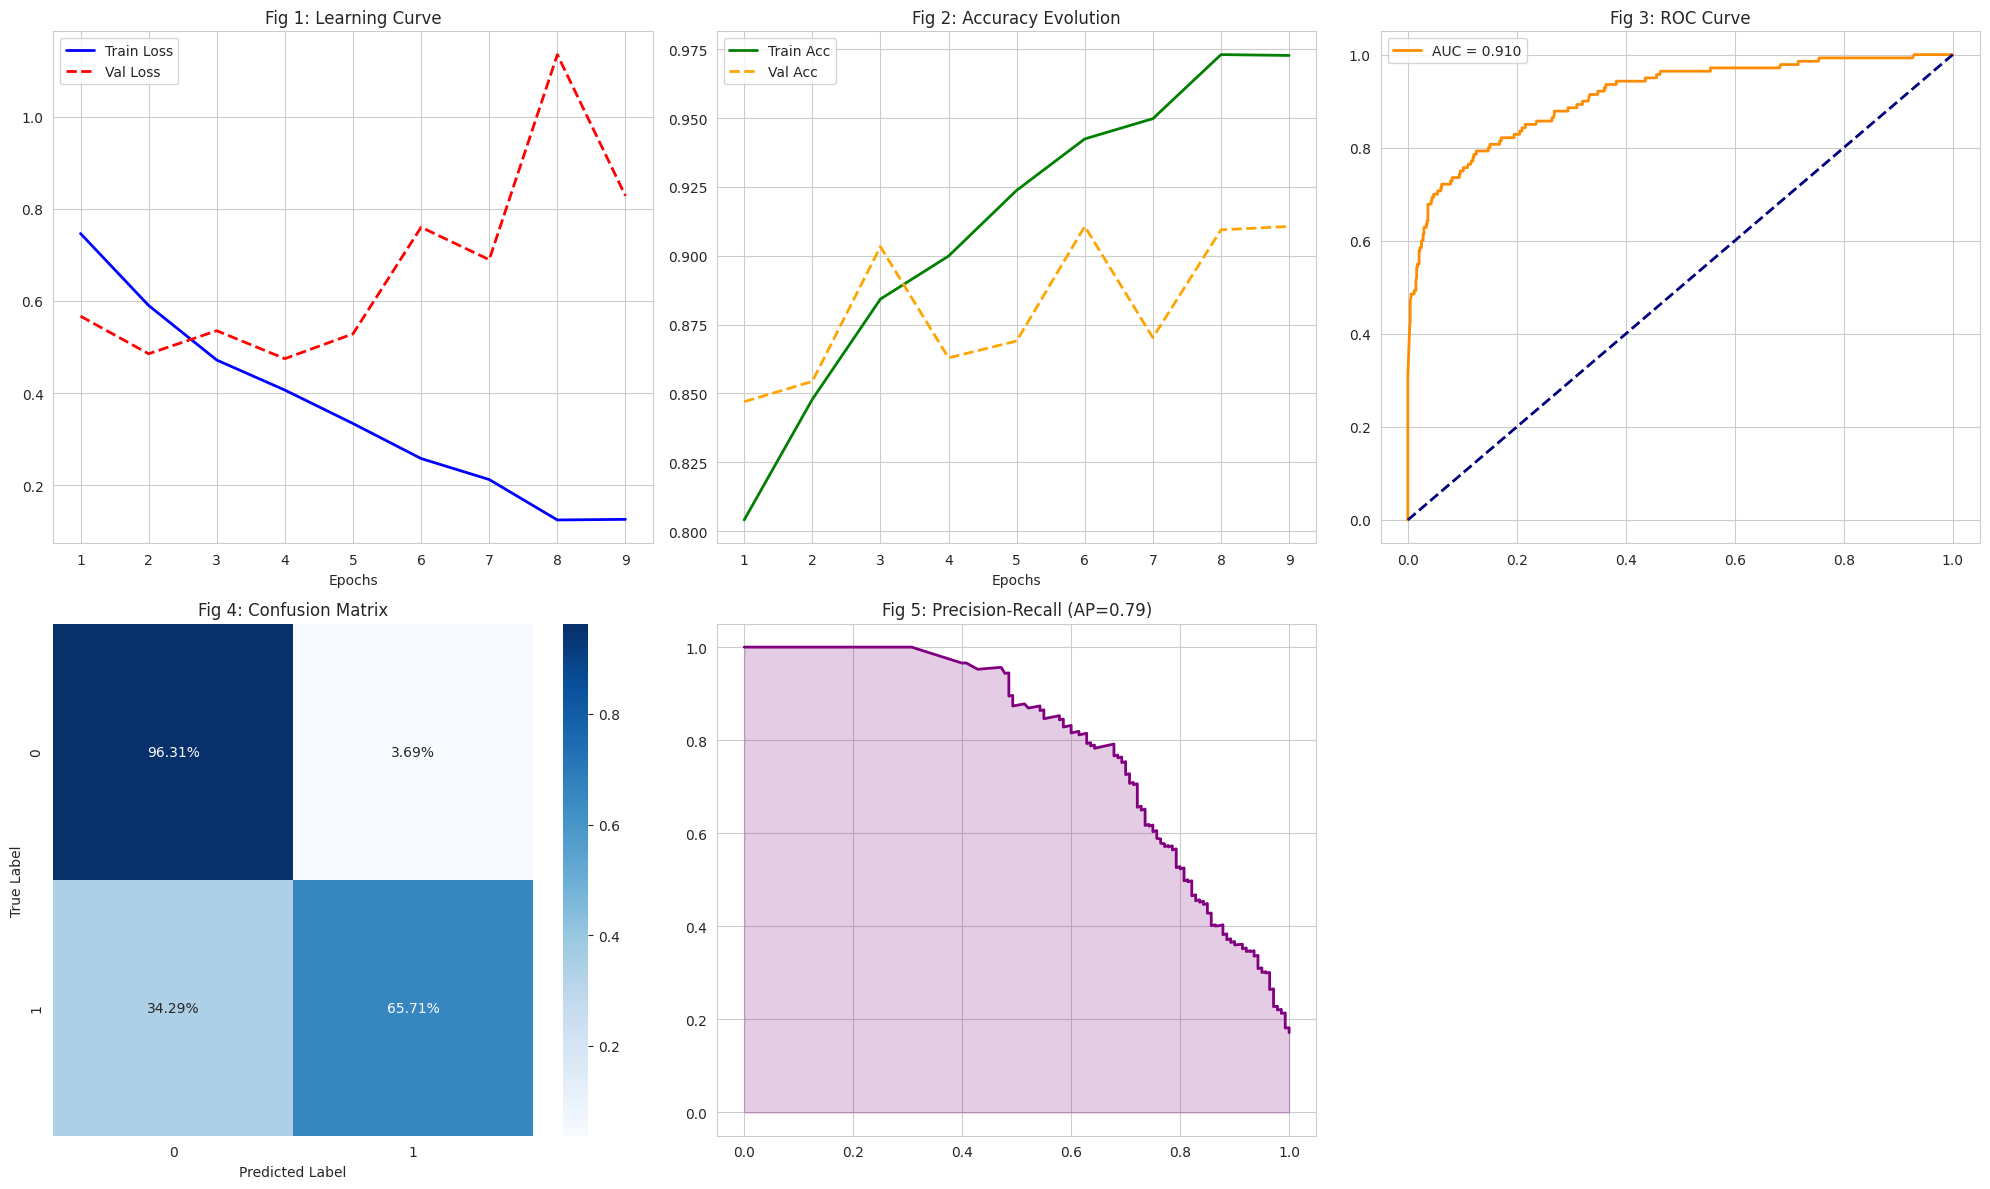

In [54]:
# ==========================================
# CELL 5: VISUALIZATION
# ==========================================

def plot_results():
    sns.set_style("whitegrid")
    plt.rcParams.update({'font.size': 10})
    fig = plt.figure(figsize=(20, 12))
    gs = fig.add_gridspec(2, 3)

    # 1. Loss Curve
    ax1 = fig.add_subplot(gs[0, 0])
    epochs = range(1, len(history['train_loss']) + 1)
    ax1.plot(epochs, history['train_loss'], label='Train Loss', color='blue', lw=2)
    ax1.plot(epochs, history['val_loss'], label='Val Loss', color='red', linestyle='--', lw=2)
    ax1.set_title("Fig 1: Learning Curve")
    ax1.set_xlabel("Epochs")
    ax1.legend()

    # 2. Accuracy Curve
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.plot(epochs, history['train_acc'], label='Train Acc', color='green', lw=2)
    ax2.plot(epochs, history['val_acc'], label='Val Acc', color='orange', linestyle='--', lw=2)
    ax2.set_title("Fig 2: Accuracy Evolution")
    ax2.set_xlabel("Epochs")
    ax2.legend()

    # 3. ROC Curve
    fpr, tpr, _ = roc_curve(true_labels_all, pred_scores_all)
    roc_auc = auc(fpr, tpr)
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.3f}')
    ax3.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax3.set_title("Fig 3: ROC Curve")
    ax3.legend()

    # 4. Confusion Matrix
    y_pred = (pred_scores_all > 0.5).astype(int)
    cm = confusion_matrix(true_labels_all, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    ax4 = fig.add_subplot(gs[1, 0])
    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', ax=ax4)
    ax4.set_title("Fig 4: Confusion Matrix")
    ax4.set_ylabel('True Label')
    ax4.set_xlabel('Predicted Label')

    # 5. Precision-Recall
    precision, recall, _ = precision_recall_curve(true_labels_all, pred_scores_all)
    avg_prec = average_precision_score(true_labels_all, pred_scores_all)

    ax5 = fig.add_subplot(gs[1, 1])
    ax5.plot(recall, precision, color='purple', lw=2)
    ax5.fill_between(recall, precision, alpha=0.2, color='purple')
    ax5.set_title(f'Fig 5: Precision-Recall (AP={avg_prec:.2f})')

    plt.tight_layout()
    plt.savefig('Research_Graphs.png', dpi=300)
    plt.show()

plot_results()

In [18]:
# ==========================================
# CELL 6: SAFE EXPORT TO ONNX
# ==========================================
import torch.onnx
import warnings

# Suppress annoying export warnings
warnings.filterwarnings("ignore", category=UserWarning)

print("Loading best weights...")
# Load the best weights saved during Early Stopping
model.load_state_dict(torch.load('best_model.pth', weights_only=True))
model.eval()

# Create a fixed dummy input (1 batch, 3 channels, 256x256)
dummy_input = torch.randn(1, 3, 256, 256).to(device)

print("Exporting model to ONNX. This may take a minute...")

try:
    # Use opset 16 to avoid the "Pad adapter" bug
    torch.onnx.export(
        model, 
        dummy_input, 
        "SwinGNN_FracAtlas.onnx", 
        export_params=True, 
        opset_version=16, 
        do_constant_folding=True,
        input_names=['input'], 
        output_names=['output']
        # Note: dynamic_axes removed to ensure stable export
    )
    print("✅ SUCCESS: Model safely saved as SwinGNN_FracAtlas.onnx")
except Exception as e:
    print(f"❌ Export Failed: {e}")

W0309 22:46:41.118000 11156 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 16 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


Loading best weights...
Exporting model to ONNX. This may take a minute...


W0309 22:46:41.507000 11156 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0309 22:46:41.508000 11156 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0309 22:46:41.510000 11156 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
W0309 22:46:41.511000 11156 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.


[torch.onnx] Obtain model graph for `SwinGNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SwinGNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 16).


[torch.onnx] Translate the graph into ONNX... ✅


Failed to convert the model to the target version 16 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/home/sakall/Documents/reco_sys/tf-env/lib/python3.12/site-packages/onnxscript/version_converter/__init__.py", line 120, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/sakall/Documents/reco_sys/tf-env/lib/python3.12/site-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/home/sakall/Documents/reco_sys/tf-env/lib/python3.12/site-packages/onnxscript/version_converter/__init__.py", line 115, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/sakall/Documents/reco_sys/tf-env/lib/python3.12/site-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_

Applied 55 of general pattern rewrite rules.
✅ SUCCESS: Model safely saved as SwinGNN_FracAtlas.onnx


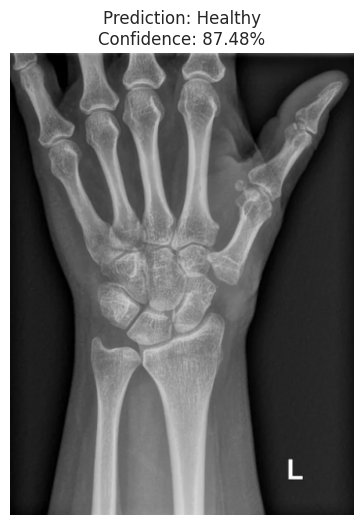

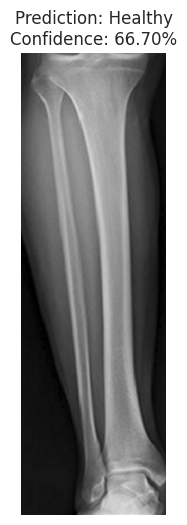

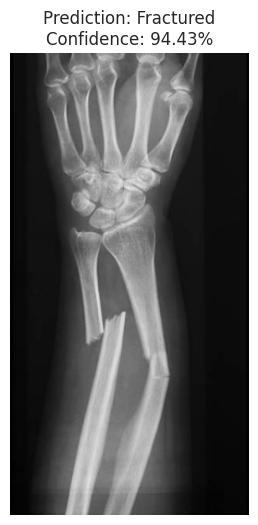

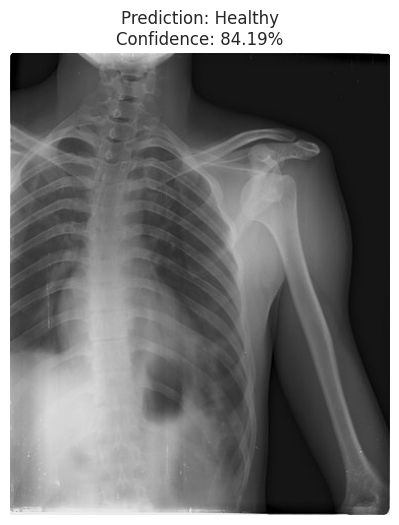

In [53]:
# ==========================================
# CELL 7: SINGLE IMAGE INFERENCE (LETTERBOX PADDING)
# ==========================================
import cv2
import torch
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
import os

def predict_image(image_path, model_path='best_model.pth'):
    if not os.path.exists(image_path):
        print(f"❌ Error: Image not found at {image_path}")
        return

    model.load_state_dict(torch.load(model_path, weights_only=True))
    model.eval()

    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    lab = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    image_clahe = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    # Added Letterboxing to maintain aspect ratio
    transform = A.Compose([
        A.LongestMaxSize(max_size=256),
        A.PadIfNeeded(min_height=256, min_width=256, border_mode=cv2.BORDER_CONSTANT, value=[0,0,0]),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

    input_tensor = transform(image=image_clahe)['image'].unsqueeze(0).to(device)

    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            output = model(input_tensor)
            probability = torch.sigmoid(output).item()

    prediction = "Fractured" if probability > 0.5 else "Healthy"
    confidence = probability if probability > 0.5 else (1 - probability)

    plt.figure(figsize=(6, 6))
    plt.imshow(image_rgb)
    plt.title(f"Prediction: {prediction}\nConfidence: {confidence:.2%}")
    plt.axis('off')
    plt.show()

# --- TEST IT ---

test_image_path = "image copy 4.png" 
predict_image(test_image_path)

test_image_path = "image copy.png" 
predict_image(test_image_path)

test_image_path = "image.png" 
predict_image(test_image_path)

test_image_path = "dataset/FracAtlas-20260307T050746Z-1-001/FracAtlas/images/Fractured/IMG0004337.jpg" 
predict_image(test_image_path)